# Liquidez: incertidumbre de transición y reserva
## Resumen
MVP pequeño: matriz nominal versus intervalos hipotéticos porfila. Una banda rectangular permite adaptar transición por tiempo/caja/régimen. NO es intervalo de confianza ni supremo definido sobre una única matriz fija. Datos sintéticos; resultados calculados abajo.

## Método y supuestos
Flujos(+1,−2),inicial(.8,.2),qnominal=(.05,.8). Intervalosq0=[.03,.07],q1=[.7,.9]. No todas las matrices conservan marginales estacionarios del ciclo27.

Tras el flujo,c'=c+g(s). Si c'<0 se absorbe riesgo1; si no quedan flujos,riesgo0. $U_h(c,s)=\max_{q\in[lo_s,hi_s]}[(1-q)U_{h-1}(c',0)+qU_{h-1}(c',1)]$. Es afín enq, así basta los extremos. La banda inferior usa min con continuacionesinferiores. Naturaleza elige de forma rectangular en cada estado/fecha, no una sola matriz para toda la trayectoria.

### Pregunta falsable
¿La cota supera nominal al menos5pp en caja6,H20?¿La reserva robusta supera nominal≥3unidades para objetivo5%? Umbrales enconfig. La búsqueda0..30 se agotó; se extendió a0..40 porque20salidas de−2 acotan pérdida máxima. No se cambió hipótesis.

In [1]:
from pathlib import Path
import json,csv
from IPython.display import display,Image
from src.model import risk_band
from src.baseline import nominal
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
print(json.dumps(metrics,indent=2))
assert metrics['hypothesis_passed']

{
  "config": {
    "cash": 6,
    "horizon": 20,
    "initial": [
      0.8,
      0.2
    ],
    "nominal_stress_probabilities": [
      0.05,
      0.8
    ],
    "bounds": [
      [
        0.03,
        0.07
      ],
      [
        0.7,
        0.9
      ]
    ],
    "buffers": 41,
    "target": 0.05,
    "hypothesis": "upper risk minus nominal risk>=0.05 at cash6 and robust minimum buffer exceeds nominal by>=3 units",
    "data": "synthetic stress intervals, not estimated confidence regions",
    "grid_note": "initial0..30 did not attain robust target; extended to0..40 because worst20flows*2=40 bounds required reserve, without changing hypothesis"
  },
  "selected": {
    "cash": 6,
    "lower": 0.12504179531622292,
    "nominal": 0.25722509658919335,
    "upper": 0.4605330392353987,
    "largest_static_corner": 0.4605330392353988,
    "adaptive_minus_static_corner": -1.1102230246251565e-16,
    "visited_states": 228
  },
  "nominal_buffer": 22,
  "robust_buffer": 34,
  "seconds

## Resultados
41reservas y cuatro esquinas estáticas por reserva, sin simulaciónaleatoria. El baseline nominal usa el forwardDP27 sin modificar; checksum enJSON. La banda proviene del modelo supuesto, no de datos estimados. Reserva34 no es recomendación para un banco real.

{'cash': '6', 'lower': '0.12504179531622292', 'nominal': '0.25722509658919335', 'upper': '0.4605330392353987', 'largest_static_corner': '0.4605330392353988', 'adaptive_minus_static_corner': '-1.1102230246251565e-16', 'visited_states': '228'}
{'cash': '22', 'lower': '0.007903545218083022', 'nominal': '0.04222850529325222', 'upper': '0.1655537764560283', 'largest_static_corner': '0.16555377645602834', 'adaptive_minus_static_corner': '-2.7755575615628914e-17', 'visited_states': '366'}
{'cash': '33', 'lower': '0.0009858596329087228', 'nominal': '0.009429411719806985', 'upper': '0.06460534299318735', 'largest_static_corner': '0.06460534299318738', 'adaptive_minus_static_corner': '-2.7755575615628914e-17', 'visited_states': '412'}
{'cash': '34', 'lower': '0.0006227851188743222', 'nominal': '0.0063613344736608325', 'upper': '0.04710377320061382', 'largest_static_corner': '0.04710377320061383', 'adaptive_minus_static_corner': '-1.3877787807814457e-17', 'visited_states': '414'}
{'cash': '40', '

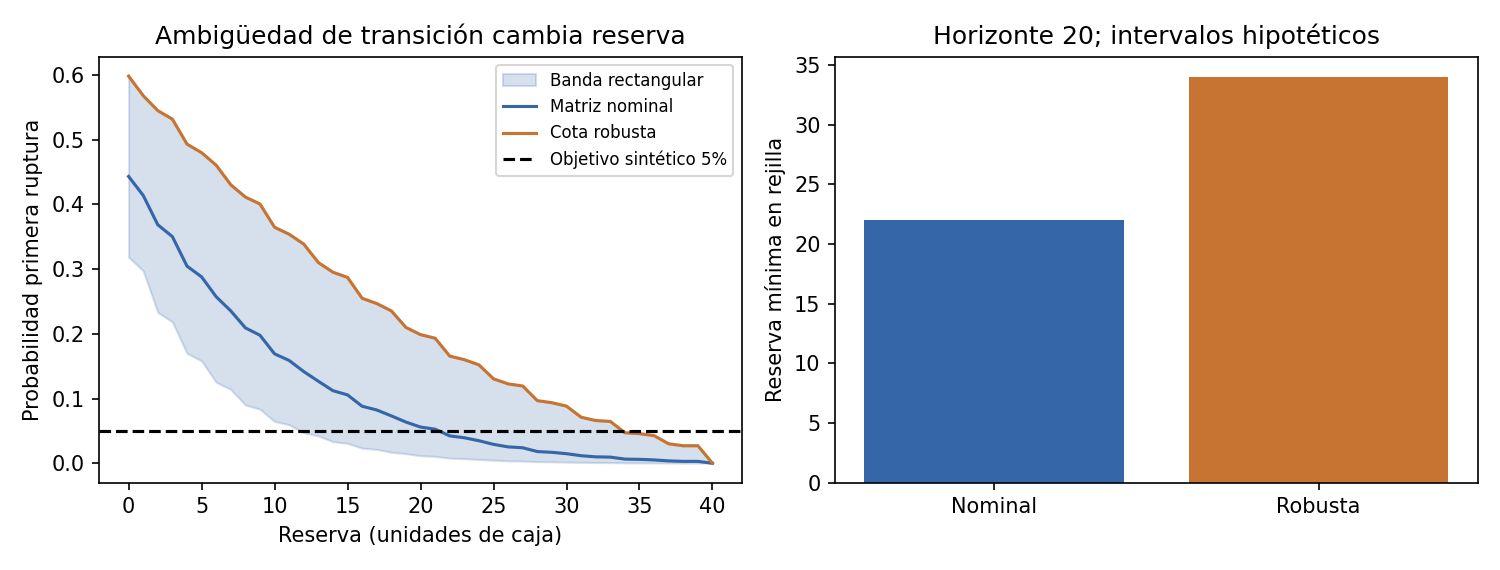

In [2]:
display(Image(filename=str(root/'results/audit.png')))
rows=list(csv.DictReader((root/'results/curves.csv').open()))
for row in rows:
 if int(row['cash']) in [6,22,33,34,40]: print(row)

## Oráculo y falsaciones
Desde caja0/régimennormal: primer flujo+1,día2estrés−2 cruza frontera; riesgo exacto=q0. H1 no depende de transición y singleton reproduce nominal. En este escenario el adversario adaptativo NO empeora una esquina fija observada: no se finge superioridad del método máscomplejo.

In [3]:
band=risk_band(0,2,[[.1,.4],[.2,.8]],[1,0])
assert band.lower==.1 and band.upper==.4
assert risk_band(1,1,[[0,1],[0,1]]).lower==risk_band(1,1,[[0,1],[0,1]]).upper
p=nominal(6,20,[.05,.8])
b=risk_band(6,20,[[.05,.05],[.8,.8]])
assert abs(b.lower-p)<1e-12 and abs(b.upper-p)<1e-12
print('Analytic/singleton checks passed')
print('Máximo gap adaptativo/esquina observado:',metrics['maximum_adaptive_static_gap'])

Analytic/singleton checks passed
Máximo gap adaptativo/esquina observado: 1.1102230246251565e-16


## Límites y siguiente iteración
Rectangularidad fuerte y rangos hipotéticos; no cobertura estadística, no equivalencia universal con matrizfija, no aprendizaje ni fondeo operativo. Añadir región de confianza temporal sería una tarea distinta. Cinco fuentes primarias e informe14p detallan supuestos y lectura. Prototipo de componente; no operación.